# Signed Statement Network

Nodes = 60 survey statements (T/E/S/V, 15 each). Edges = Pearson correlation of
respondents' answers across the two statements, sign retained. This is a
different graph class from the respondent-similarity network (Vishal). Here
we ask which issues move together or in opposition across the class, not
which people are alike.

Pipeline: load & clean (fresh from `Survey_Results_UC.csv`) -> per-item z-score -> pairwise
correlation matrix -> permutation-test + FDR edge selection (signed) ->
structure (communities vs. T/E/S/V blocks, hub ranking, structural balance /
frustration) -> dynamics (Altafini signed consensus, perturbation leverage).


In [1]:
import sys
from pathlib import Path

# This member's own modules. `common` needs no path work -- it is an
# installed package (pip install -e .), so it imports from any directory.
SRC = Path.cwd() / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score

import build as B
import balance as BAL
import diffusion as D
from common import viz
from common.contract import REVERSE_CODE_FLAGGED as FLAGGED_ITEMS
from load import SEED, item_blocks, item_wording, load_clean

FIG_DIR = Path.cwd() / "figures"
TAB_DIR = Path.cwd() / "tables"
viz.apply_style()
np.random.seed(SEED)


## 1. Load & clean

Loaded through `common/contract.py`, the one shared data contract all three
members import: `Survey_Results_UC.csv`, Likert text -> 1-5,
`No Comments`/blank -> NaN (never Neutral), then drop rows missing more than
30 of 60 answers, leaving 87 respondents. Dropping any row with a single
missing answer would leave 85 and cost two respondents for no reason.


In [2]:
coded = load_clean()
wording = item_wording()
blocks = item_blocks(coded.columns)
print(f"Respondents: {coded.shape[0]} (expected 87), Items: {coded.shape[1]} (expected 60)")
print("Missing values per item (top 5):")
coded.isna().sum().sort_values(ascending=False).head()


Respondents: 87 (expected 87), Items: 60 (expected 60)
Missing values per item (top 5):


V06    3
V11    3
S10    3
S14    3
V12    3
dtype: int64

### Response distribution (the ceiling effect)

Every one of the 87x60 cells is a 1-5 Likert code (or NaN). Plotting the raw
response distribution, overall and per block, makes the ceiling effect concrete before any network is built. It is the reason raw
similarity is a near-clique and z-scoring / signed-correlation is required.

In [3]:
cat_names = ["Strongly\nDisagree", "Disagree", "Neutral", "Agree", "Strongly\nAgree"]
overall_counts = coded.stack().value_counts().reindex([1, 2, 3, 4, 5]).fillna(0)
n_missing = int(coded.isna().sum().sum())
pct_agree = (overall_counts[4] + overall_counts[5]) / overall_counts.sum()
block_means = pd.DataFrame({"item": coded.columns, "mean": coded.mean(), "block": blocks})

print(f"{int(overall_counts.sum())} answered cells (+{n_missing} missing/'No Comments')")
print(f"Agree or Strongly Agree: {pct_agree:.1%}  <- the ceiling effect that forces z-scoring")
print(f"Items with a mean below neutral (3.0): {(block_means['mean'] < 3.0).sum()} / 60")
block_means.sort_values("mean").head(3)

5158 answered cells (+62 missing/'No Comments')
Agree or Strongly Agree: 80.0%  <- the ceiling effect that forces z-scoring
Items with a mean below neutral (3.0): 2 / 60


,item,mean,block
E03,E03,2.057471,E
E02,E02,2.839080,E
T08,T08,3.069767,T


## 2. Correlation matrix and its sensitivity to missing-data handling

Pearson correlation is invariant to per-item z-scoring, so the primary
correlation matrix is identical whether computed on raw 1-5 codes or
z-scored items. The real arbitrary choice is how missing values are
handled, i.e., pairwise-complete deletion (primary) vs. mean-imputing z-scores to
0 (sensitivity check).

In [4]:
corr_primary = B.pairwise_complete_corr(coded)
corr_alt = B.mean_imputed_corr(coded)
iu = np.triu_indices(60, 1)
diff = np.abs(corr_primary.values[iu] - corr_alt.values[iu])
print(f"Missing-data handling sensitivity: mean |delta r| = {diff.mean():.4f}, max = {diff.max():.4f}")
print("-> negligible: missingness is light (at most a few per item) and unsystematic, so pairwise-complete")
print("   correlation and mean-imputed-zscore correlation agree almost exactly. We use pairwise-complete.")


Missing-data handling sensitivity: mean |delta r| = 0.0033, max = 0.0694
-> negligible: missingness is light (at most a few per item) and unsystematic, so pairwise-complete
   correlation and mean-imputed-zscore correlation agree almost exactly. We use pairwise-complete.


## 3. Edge selection: permutation test + FDR (primary) vs. fixed threshold (sensitivity)

Primary rule: for each pair, build a null distribution of |r| by independently
permuting each item's answers across respondents (destroys real cross-item
covariance, keeps each item's own marginal distribution and missingness
pattern), pool null |r| across all 1770 pairs and `N_PERMUTATIONS` shuffles,
get an empirical two-sided p-value per real edge, then apply Benjamini-Hochberg
FDR at q=0.05. A single family-wise max-statistic threshold (alpha=0.01) was
tried first and rejected, i.e., at |r| > 0.50 it kept only positive edges, which
would erase the very structure (negative correlations) this network exists to
show.

Sensitivity rule: a fixed |r| > 0.30 cutoff, no significance testing.

In [5]:
null_pool = B.permutation_null_pool(coded, n_perm=B.N_PERMUTATIONS, seed=SEED)
edge_p = B.permutation_edge_pvalues(corr_primary, null_pool)
mask = B.fdr_bh_threshold_mask(edge_p["p"].to_numpy(), B.FDR_Q)
keep_pairs = set(zip(edge_p.loc[mask, "i"], edge_p.loc[mask, "j"]))
print(f"FDR-significant pairs (q={B.FDR_Q}): {mask.sum()} / {len(mask)}")
print(f"Smallest |r| retained: {edge_p.loc[mask, 'r'].abs().min():.3f}")

G = B.build_signed_graph(corr_primary, block_of=blocks, keep_pairs=keep_pairs)
G_alt = B.build_signed_graph(corr_primary, threshold=B.FIXED_R_THRESHOLD, block_of=blocks)

summary_primary = B.graph_summary(G)
summary_alt = B.graph_summary(G_alt)
sensitivity_df = pd.DataFrame([
    {"rule": "permutation+FDR (primary)", **summary_primary},
    {"rule": f"fixed |r|>{B.FIXED_R_THRESHOLD} (sensitivity)", **summary_alt},
])
sensitivity_df.to_csv(TAB_DIR / "table00_edge_rule_sensitivity.csv", index=False)
sensitivity_df


FDR-significant pairs (q=0.05): 402 / 1770
Smallest |r| retained: 0.274


,rule,n_nodes,n_edges,n_positive,n_negative,density,n_isolates
0,permutation+FDR (primary),60,402,391,11,0.227119,2
1,fixed |r|>0.3 (sensitivity),60,316,312,4,0.178531,4


In [6]:
edge_rows = [{"item_i": u, "item_j": v, "r": d["r"], "sign": d["sign"]} for u, v, d in G.edges(data=True)]
edge_df = pd.DataFrame(edge_rows).sort_values("r", key=np.abs, ascending=False).reset_index(drop=True)
edge_df.to_csv(TAB_DIR / "table01_edge_list.csv", index=False)
print(f"Negative edges ({summary_primary['n_negative']}):")
edge_df[edge_df["sign"] < 0]


Negative edges (11):


,item_i,item_j,r,sign
54,E03,E10,-0.440390,-1
241,T03,E04,-0.322569,-1
275,E01,E02,-0.314373,-1
307,T06,E03,-0.302187,-1
322,E03,E07,-0.296841,-1
336,E03,S06,-0.292334,-1
373,T01,T12,-0.281604,-1
377,E03,E11,-0.279346,-1
379,T14,E03,-0.278915,-1
383,E03,E12,-0.277154,-1


### Distribution of all 1770 pairwise correlations vs. the permutation null

Direct visual of the significance test behind edge selection: the real
correlation distribution against the pooled null distribution generated by
permuting each item independently. Edges are kept where the real distribution
sticks out beyond the null.

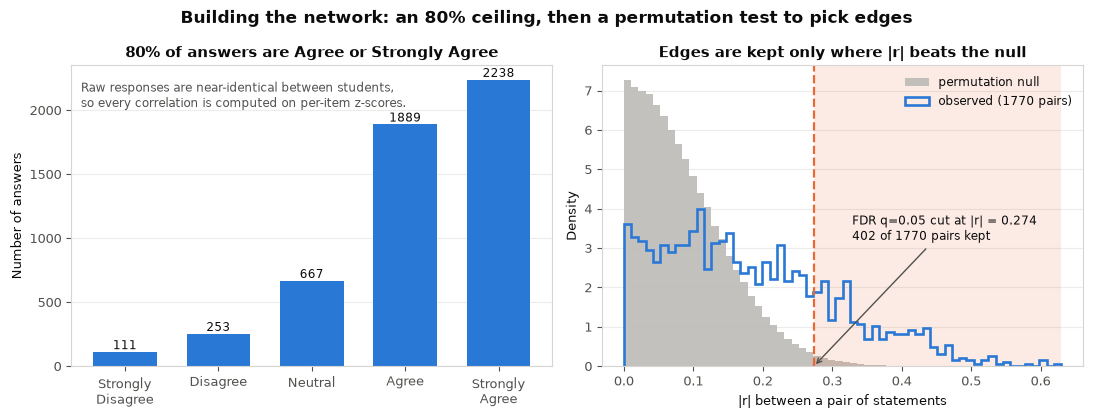

Observed |r|: mean 0.180, max 0.630
Null |r|:     mean 0.087, 99th pct 0.278
Kept: 402 edges, smallest |r| retained = 0.274


In [7]:
real_r = np.abs(corr_primary.values[iu])
kept_r = np.abs(edge_p.loc[mask, "r"].to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# (a) the ceiling effect -- why per-item z-scoring is not optional
ax = axes[0]
bars = ax.bar(cat_names, overall_counts.values, color=viz.CAT[0], width=0.68)
for b, v in zip(bars, overall_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{int(v)}", ha="center", va="bottom",
            fontsize=8.5, color=viz.INK)
ax.set_ylabel("Number of answers")
ax.set_title(f"{pct_agree:.0%} of answers are Agree or Strongly Agree")
ax.grid(axis="x", visible=False)
ax.text(0.02, 0.95, "Raw responses are near-identical between students,\nso every correlation is computed on per-item z-scores.",
        transform=ax.transAxes, va="top", fontsize=8.5, color=viz.INK_SOFT)

# (b) which correlations survive, and why
ax = axes[1]
# both histograms are normalised over the SAME 1770 pairs, so their heights are
# directly comparable; the kept set is shown as a shaded region rather than a
# third histogram, which would be normalised over a subset and tower misleadingly
bins = np.linspace(0, max(real_r.max(), null_pool.max()), 61)
ax.hist(null_pool, bins=bins, density=True, color=viz.NULL, alpha=0.85,
        label="permutation null")
ax.hist(real_r, bins=bins, density=True, histtype="step", lw=1.9, color=viz.CAT[0],
        label=f"observed ({len(real_r)} pairs)")
cut = kept_r.min()
ax.axvspan(cut, bins[-1], color=viz.CAT[1], alpha=0.13, lw=0)
ax.axvline(cut, color=viz.CAT[1], ls="--", lw=1.6)
ax.set_xlabel("|r| between a pair of statements")
ax.set_ylabel("Density")
ax.set_title("Edges are kept only where |r| beats the null")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8.5, loc="upper right")
ax.annotate(f"FDR q=0.05 cut at |r| = {cut:.3f}\n{mask.sum()} of {len(real_r)} pairs kept",
            xy=(cut, 0), xycoords="data", xytext=(0.52, 0.42), textcoords="axes fraction",
            fontsize=8.5, color=viz.INK,
            arrowprops=dict(arrowstyle="->", color=viz.INK_SOFT, lw=1))

fig.suptitle("Building the network: an 80% ceiling, then a permutation test to pick edges",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_construction.png")
plt.show()

print(f"Observed |r|: mean {real_r.mean():.3f}, max {real_r.max():.3f}")
print(f"Null |r|:     mean {null_pool.mean():.3f}, 99th pct {np.quantile(null_pool, 0.99):.3f}")
print(f"Kept: {mask.sum()} edges, smallest |r| retained = {kept_r.min():.3f}")

## 4. Network visualization

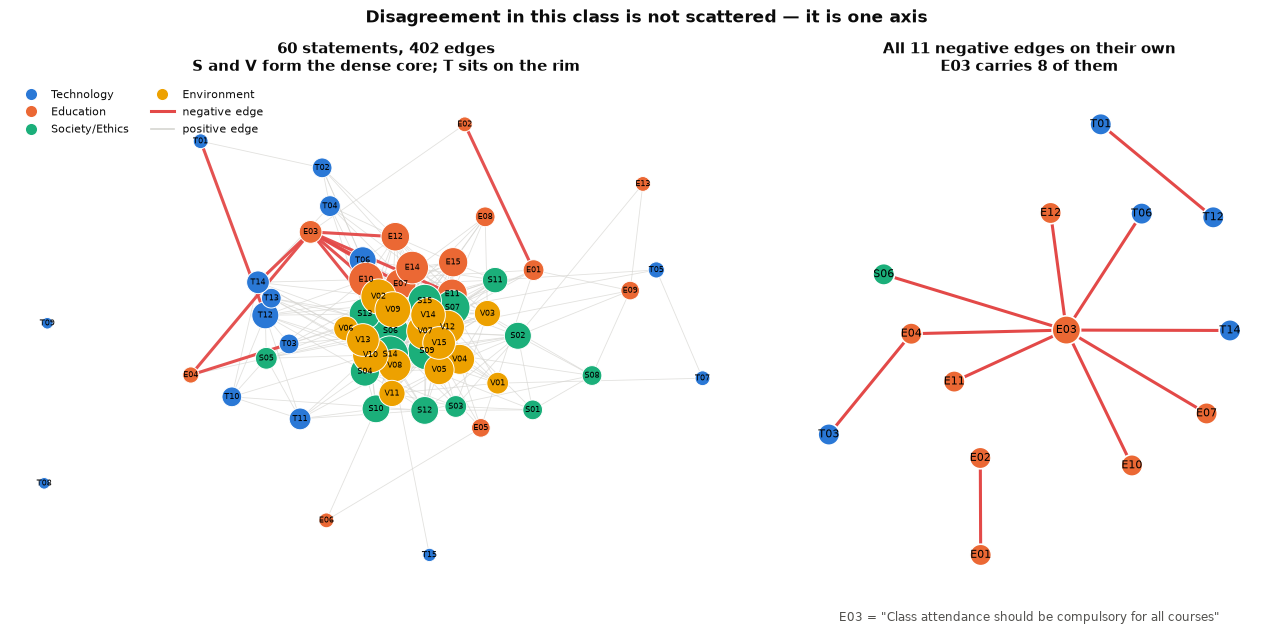

Negative-edge subgraph: 14 statements, 11 edges
degrees: {'E03': 8, 'E04': 2, 'T01': 1, 'T12': 1, 'T03': 1, 'T06': 1, 'T14': 1, 'E01': 1, 'E02': 1, 'E07': 1, 'E10': 1, 'E11': 1, 'E12': 1, 'S06': 1}


In [8]:
fig = plt.figure(figsize=(13, 6.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1])

# ---- (a) the whole signed network ----
ax = fig.add_subplot(gs[0, 0])
pos = nx.spring_layout(G, weight="weight", seed=SEED, k=0.35)
pos_edges = [(u, v) for u, v, d in G.edges(data=True) if d["sign"] > 0]
neg_edges = [(u, v) for u, v, d in G.edges(data=True) if d["sign"] < 0]

nx.draw_networkx_edges(G, pos, edgelist=pos_edges, edge_color="#d6d5d1", width=0.6, alpha=0.7, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=neg_edges, edge_color=viz.DIV_POS, width=2.2, alpha=0.95, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=[viz.BLOCK_COLORS[blocks[n]] for n in G.nodes()],
                       node_size=[70 + 22 * G.degree(n) for n in G.nodes()],
                       edgecolors="white", linewidths=0.7, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
ax.set_title("60 statements, 402 edges\nS and V form the dense core; T sits on the rim", fontsize=10.5)
ax.axis("off")

handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=viz.BLOCK_COLORS[k],
                      markersize=9, label=viz.BLOCK_NAMES[k]) for k in "TESV"]
handles.append(plt.Line2D([0], [0], color=viz.DIV_POS, lw=2.2, label="negative edge"))
handles.append(plt.Line2D([0], [0], color="#d6d5d1", lw=1.2, label="positive edge"))
ax.legend(handles=handles, loc="upper left", fontsize=8, ncol=2)

# ---- (b) only the 11 negative edges ----
ax = fig.add_subplot(gs[0, 1])
N = nx.Graph()
N.add_edges_from([(u, v, {"r": d["r"]}) for u, v, d in G.edges(data=True) if d["sign"] < 0])
npos = nx.spring_layout(N, seed=SEED, k=0.9)
nx.draw_networkx_edges(N, npos, edge_color=viz.DIV_POS, width=2.2, ax=ax)
nx.draw_networkx_nodes(N, npos, node_color=[viz.BLOCK_COLORS[n[0]] for n in N.nodes()],
                       node_size=[420 if n == "E03" else 240 for n in N.nodes()],
                       edgecolors="white", linewidths=1.2, ax=ax)
nx.draw_networkx_labels(N, npos, font_size=8, ax=ax)
deg_e03 = N.degree("E03")
ax.set_title(f"All {N.number_of_edges()} negative edges on their own\n"
             f"E03 carries {deg_e03} of them", fontsize=10.5)
ax.axis("off")
ax.text(0.5, -0.04, 'E03 = "Class attendance should be compulsory for all courses"',
        transform=ax.transAxes, ha="center", fontsize=8.5, color=viz.INK_SOFT)

fig.suptitle("Disagreement in this class is not scattered — it is one axis",
             fontsize=12.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig02_signed_network.png")
plt.show()

print(f"Negative-edge subgraph: {N.number_of_nodes()} statements, {N.number_of_edges()} edges")
print("degrees:", dict(sorted(N.degree(), key=lambda x: -x[1])))

### Degree distribution

Only 60 nodes, so a plain histogram (not log-binned. Too few nodes/too
narrow a range for log binning to be meaningful, unlike Vishal's 87-node
respondent network) is the right view. Split by sign shows most statements
owe their whole degree to positive edges, only the handful touching E03 carry
negative degree.

In [9]:
degrees = dict(G.degree())
pos_degree = {n: sum(1 for _, d in G[n].items() if d["sign"] > 0) for n in G.nodes()}
neg_degree = {n: sum(1 for _, d in G[n].items() if d["sign"] < 0) for n in G.nodes()}

## 5. Communities vs. the survey's own T/E/S/V blocks

Community detection runs on the positive-edge subgraph (modularity is
unstable with mixed-sign weights; negative edges are analysed separately via
structural balance below). Compared against the survey's own T/E/S/V labels
with normalized mutual information (NMI).

In [10]:
comm = B.detect_communities(G, seed=SEED)
nodelist = list(G.nodes())
comm_labels = [comm[n] for n in nodelist]
block_labels = [blocks[n] for n in nodelist]
nmi = normalized_mutual_info_score(block_labels, comm_labels)
n_comm = len(set(comm_labels))
print(f"Louvain communities on positive backbone: {n_comm}")
print(f"NMI(detected community, T/E/S/V block) = {nmi:.3f}  (0 = unrelated, 1 = identical partitions)")

comm_df = pd.DataFrame({"item": nodelist, "block": block_labels, "community": comm_labels})
comm_df.to_csv(TAB_DIR / "table02_communities.csv", index=False)
crosstab = pd.crosstab(comm_df["block"], comm_df["community"])
crosstab.to_csv(TAB_DIR / "table02b_block_by_community_crosstab.csv")
crosstab


Louvain communities on positive backbone: 8
NMI(detected community, T/E/S/V block) = 0.277  (0 = unrelated, 1 = identical partitions)


community,0,1,2,3,4,5,6,7
block,,,,,,,,
E,0,0,2,7,5,0,1,0
S,0,0,0,2,8,2,1,2
T,1,1,0,6,0,5,1,1
V,0,0,0,3,2,0,3,7


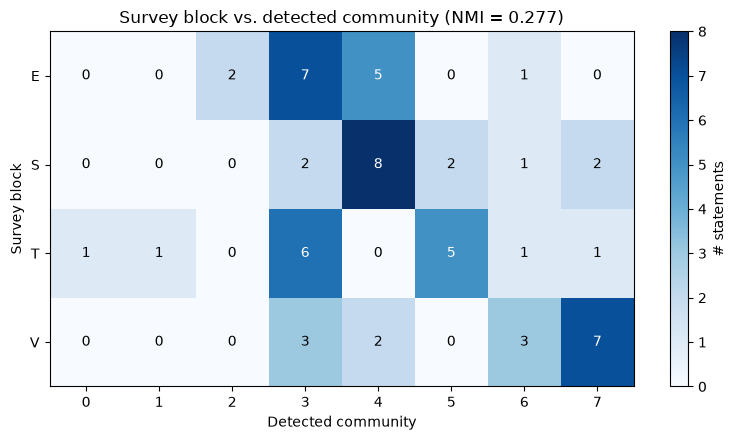

## 6. Hub and isolated statements

Node strength = sum of |r| over retained edges, split by sign.

In [11]:
hubs = B.hub_ranking(G)
hubs.to_csv(TAB_DIR / "table03_hub_ranking.csv", index=False)
print("Top 8 hubs:")
display(hubs.head(8))
print("Bottom 5 (most isolated):")
display(hubs.tail(5))


Top 8 hubs:


,item,block,degree,pos_strength,neg_strength,total_strength
0,S09,S,31,11.635319,0.000000,11.635319
1,V07,V,29,10.984968,0.000000,10.984968
2,S14,S,29,10.828174,0.000000,10.828174
3,V09,V,27,10.779323,0.000000,10.779323
4,V10,V,27,10.409356,0.000000,10.409356
5,S06,S,27,9.509089,0.292334,9.801423
6,E10,E,25,9.355215,0.440390,9.795605
7,V02,V,26,9.595928,0.000000,9.595928


Bottom 5 (most isolated):


,item,block,degree,pos_strength,neg_strength,total_strength
55,E02,E,2,0.284625,0.314373,0.598998
56,E13,E,2,0.556978,0.000000,0.556978
57,T15,T,1,0.273857,0.000000,0.273857
58,T08,T,0,0.000000,0.000000,0.000000
59,T09,T,0,0.000000,0.000000,0.000000


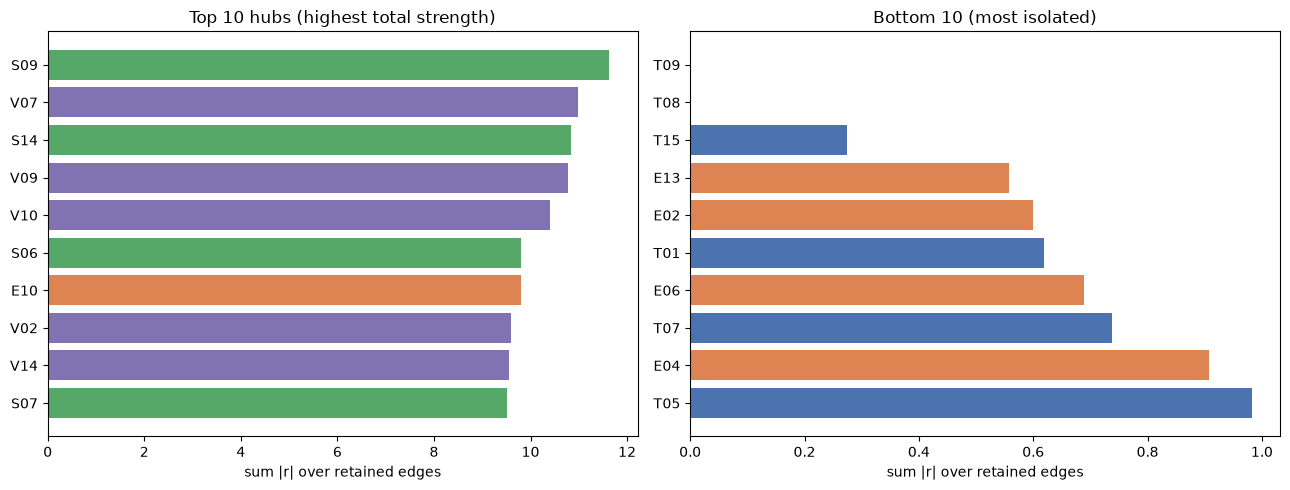

### Node strength distribution

Total strength for all 60 statements at once (the bar chart above only shows
the extremes), i.e. is there a smooth spread, or a clear hub/periphery split?

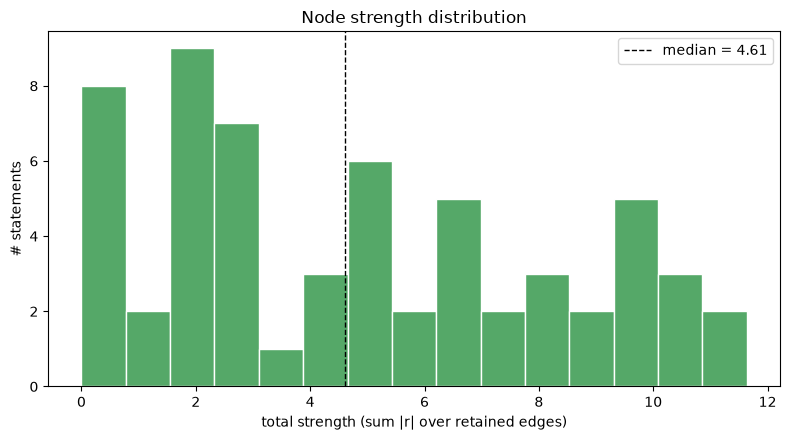

## 7. Structural balance and frustration

Closed-triad balance: a triangle is balanced if the product of its three
edge signs is positive. 

Frustration index: minimum number of edge-sign flips
(greedy local search / correlation-clustering heuristic, 50 random restarts)
needed to make the whole graph perfectly two-factional. 

Compared against a
null model that reshuffles which existing edges carry the negative sign
(topology and the 391/11 positive/negative split held fixed).

In [12]:
census = BAL.triad_census(G)
frust = BAL.frustration_index(G, seed=SEED)
null_dist = BAL.frustration_null_distribution(G, seed=SEED)
z = (frust["frustration_index"] - null_dist.mean()) / null_dist.std()

print(f"Closed triads: {census['n_closed_triads']}, unbalanced (frustrated): {census['n_unbalanced']} "
      f"({1 - census['frac_balanced']:.1%})")
print(f"Frustration index: {frust['frustration_index']} / {frust['n_edges']} edges "
      f"({frust['frustration_fraction']:.2%})")
print(f"Null (sign-shuffled) frustration: {null_dist.mean():.2f} +/- {null_dist.std():.2f}, z = {z:.1f}")

faction = frust["faction_assignment"]
faction_df = pd.DataFrame({"item": list(faction.keys()), "faction": list(faction.values())})
faction_df["block"] = faction_df["item"].map(blocks)
faction_df["degree"] = faction_df["item"].map(lambda n: G.degree(n))
faction_df.to_csv(TAB_DIR / "table04_factions.csv", index=False)

# isolated (degree-0) nodes have no edges to satisfy, so their spin is never
# updated by the local search and is meaningless -- exclude them before
# reading off which items form the minority faction
connected_factions = faction_df[faction_df["degree"] > 0]
minority = connected_factions["faction"].value_counts().idxmin()
print("Minority faction among connected statements (the 'odd ones out' in the best 2-coloring):",
      connected_factions.loc[connected_factions.faction == minority, "item"].tolist())
print("(isolated statements excluded from this call:",
      faction_df.loc[faction_df["degree"] == 0, "item"].tolist(), "-- their faction label is arbitrary)")

balance_summary = pd.DataFrame([{
    "n_edges": summary_primary["n_edges"], "n_positive": summary_primary["n_positive"],
    "n_negative": summary_primary["n_negative"], "n_closed_triads": census["n_closed_triads"],
    "n_unbalanced_triads": census["n_unbalanced"], "frustration_index": frust["frustration_index"],
    "frustration_fraction": frust["frustration_fraction"], "null_frustration_mean": null_dist.mean(),
    "null_frustration_sd": null_dist.std(), "z_score": z, "nmi_block_vs_community": nmi,
}])
balance_summary.to_csv(TAB_DIR / "table05_balance_summary.csv", index=False)
balance_summary


Closed triads: 1298, unbalanced (frustrated): 0 (0.0%)
Frustration index: 2 / 402 edges (0.50%)
Null (sign-shuffled) frustration: 10.98 +/- 0.16, z = -56.2
Minority faction among connected statements (the 'odd ones out' in the best 2-coloring): ['T01', 'E02', 'E03']
(isolated statements excluded from this call: ['T08', 'T09'] -- their faction label is arbitrary)


,n_edges,n_positive,n_negative,n_closed_triads,n_unbalanced_triads,frustration_index,frustration_fraction,null_frustration_mean,null_frustration_sd,z_score,nmi_block_vs_community
0,402,391,11,1298,0,2,0.004975,10.978,0.159737,-56.204787,0.277391


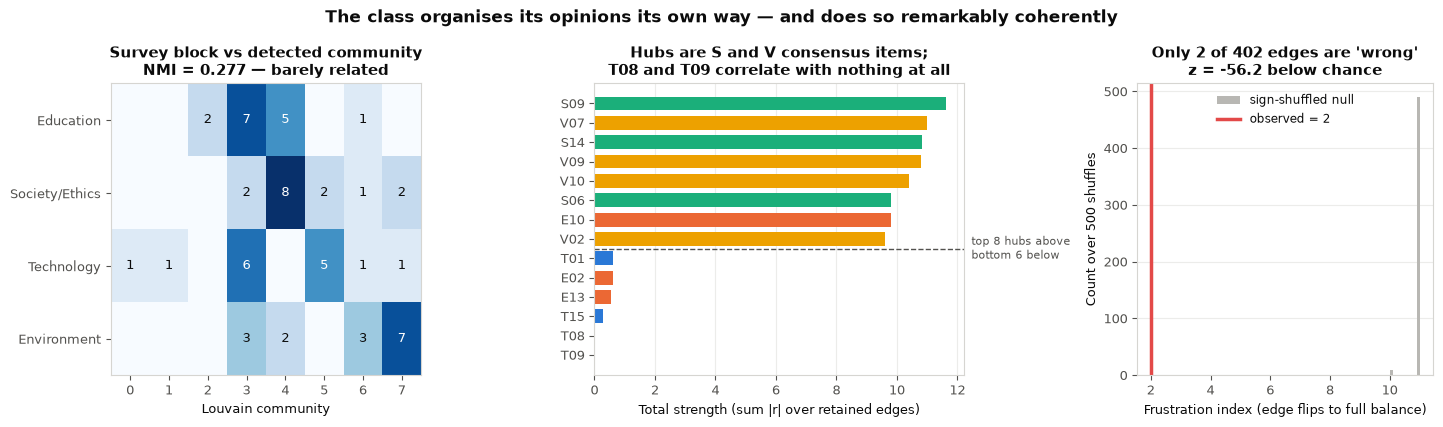

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3), gridspec_kw={"width_ratios": [1.05, 1.25, 1]})

# ---- (a) the survey's own categories vs what the class actually does ----
ax = axes[0]
im = ax.imshow(crosstab.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(crosstab.shape[1])); ax.set_xticklabels(crosstab.columns)
ax.set_yticks(range(crosstab.shape[0]))
ax.set_yticklabels([viz.BLOCK_NAMES.get(b, b) for b in crosstab.index])
for a in range(crosstab.shape[0]):
    for b in range(crosstab.shape[1]):
        v = crosstab.values[a, b]
        if v:
            ax.text(b, a, v, ha="center", va="center", fontsize=9,
                    color="white" if v > crosstab.values.max() / 2 else viz.INK)
ax.set_xlabel("Louvain community")
ax.set_title(f"Survey block vs detected community\nNMI = {nmi:.3f} — barely related", fontsize=10.5)
ax.grid(False)

# ---- (b) which statements anchor the network, and which float free ----
ax = axes[1]
sel = pd.concat([hubs.head(8), hubs.tail(6)])
sel = sel.iloc[::-1]
ax.barh(sel["item"], sel["total_strength"],
        color=[viz.BLOCK_COLORS[b] for b in sel["block"]], height=0.72)
ax.axhline(5.5, color=viz.INK_SOFT, lw=1, ls="--")
ax.text(1.02, 5.5, "top 8 hubs above\nbottom 6 below",
        transform=ax.get_yaxis_transform(), ha="left", va="center",
        fontsize=8, color=viz.INK_SOFT, clip_on=False)
ax.set_xlabel("Total strength (sum |r| over retained edges)")
ax.set_title("Hubs are S and V consensus items;\nT08 and T09 correlate with nothing at all", fontsize=10.5)
ax.grid(axis="y", visible=False)

# ---- (c) structural balance against a sign-shuffled null ----
ax = axes[2]
ax.hist(null_dist, bins=20, color=viz.NULL, label="sign-shuffled null")
ax.axvline(frust["frustration_index"], color=viz.DIV_POS, lw=2.5,
           label=f"observed = {frust['frustration_index']}")
ax.set_xlabel("Frustration index (edge flips to full balance)")
ax.set_ylabel(f"Count over {len(null_dist)} shuffles")
ax.set_title(f"Only {frust['frustration_index']} of 402 edges are 'wrong'\nz = {z:.1f} below chance", fontsize=10.5)
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8.5, loc="upper center")

fig.suptitle("The class organises its opinions its own way — and does so remarkably coherently",
             fontsize=12.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig03_structure.png")
plt.show()

### Are E02 / T10 the contrarian statements?

`E02` ("Traditional written examinations accurately measure a
student's knowledge") and `T10` ("Protection of personal data is more
important than technological convenience") are flagged as candidates for reverse-coded
phrasing. Since the network keeps sign, we don't flip them, instead we check
whether they land as genuine outliers in the balance structure.

In [14]:
for it in FLAGGED_ITEMS:
    if it in G:
        edges = [(v, round(d["r"], 3)) for v, d in G[it].items()]
        print(f"{it} ({wording[it][:60]}...)")
        print(f"  faction: {faction.get(it)}  |  degree: {G.degree(it)}  |  edges: {edges}")
    else:
        print(f"{it}: isolated (no significant edges)")


E02 (Traditional written examinations accurately measure a studen...)
  faction: 1  |  degree: 2  |  edges: [('E01', -0.314), ('E03', 0.285)]
T10 (Protection of personal data is more important than technolog...)
  faction: -1  |  degree: 6  |  edges: [('T11', 0.298), ('T12', 0.447), ('T14', 0.306), ('S05', 0.464), ('S12', 0.291), ('V10', 0.284)]


## 8. Dynamics: signed (Altafini) consensus and opinion-leverage perturbation

Unsigned Laplacian consensus always converges to a single weighted average on
a connected component. It can't show fragmentation, only speed. The signed
(Altafini) Laplacian `dx/dt = -L_signed x` can, i.e., on a connected signed graph it
reaches bipartite consensus (opinions settle into two mirror-image factions)
iff the graph is structurally balanced. Any frustration makes every
opinion decay toward 0. We seed it with each statement's actual
deviation-from-neutral (mean response - 3) and watch what happens.

In [15]:
giant_nodes = max(nx.connected_components(G), key=len)
Gc = G.subgraph(giant_nodes).copy()
gc_nodelist = list(Gc.nodes())
print(f"Giant component: {len(gc_nodelist)} / {G.number_of_nodes()} statements")

mean_dev = coded[gc_nodelist].mean() - 3.0
demo = D.signed_consensus_demo(Gc, gc_nodelist, mean_dev.to_dict(), t_max=D.T_MAX_TRAJECTORY)
print(f"Altafini dynamics: mean |opinion| goes {demo['initial_abs_mean']:.3f} -> {demo['final_abs_mean']:.3f} "
      f"over t in [0, {D.T_MAX_TRAJECTORY}]")
print("-> slow decay toward 0, consistent with near-but-not-exact balance (frustration index = "
      f"{frust['frustration_index']}, not 0): a handful of longer signed cycles (not caught by the "
      "triangle census, which found zero unbalanced triangles) block a perfectly stable bipartite split.")


Giant component: 58 / 60 statements
Altafini dynamics: mean |opinion| goes 1.215 -> 0.080 over t in [0, 120.0]
-> slow decay toward 0, consistent with near-but-not-exact balance (frustration index = 2, not 0): a handful of longer signed cycles (not caught by the triangle census, which found zero unbalanced triangles) block a perfectly stable bipartite split.


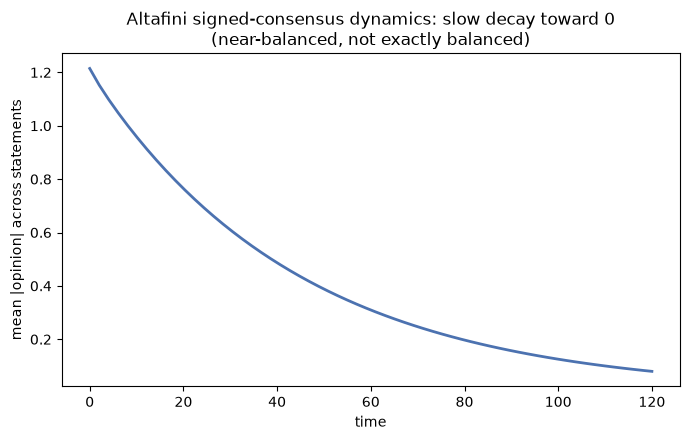

### Perturbation experiment: opinion leverage ranking

Nudge one statement's opinion by one unit and measure the total signed
magnitude of movement it propagates through the rest of the issue graph
within a fixed time horizon (`T_HORIZON`).

In [16]:
leverage = D.perturbation_leverage(Gc, gc_nodelist, t=D.T_HORIZON)
lev_df = pd.DataFrame({"item": gc_nodelist, "leverage": leverage, "block": [blocks[n] for n in gc_nodelist]})
lev_df = lev_df.sort_values("leverage", ascending=False).reset_index(drop=True)
lev_df.to_csv(TAB_DIR / "table06_leverage_ranking.csv", index=False)
print("Top 8 highest-leverage statements (nudging these moves the most of the rest of the class's issue graph):")
display(lev_df.head(8))
print("Bottom 5 lowest-leverage:")
display(lev_df.tail(5))


Top 8 highest-leverage statements (nudging these moves the most of the rest of the class's issue graph):


,item,leverage,block
0,S09,0.967362,S
1,V10,0.966542,V
2,S14,0.966178,S
3,V13,0.965863,V
4,V15,0.965671,V
5,V12,0.965509,V
6,V08,0.965393,V
7,S07,0.965322,S


Bottom 5 lowest-leverage:


,item,leverage,block
53,E02,0.415933,E
54,E13,0.399141,E
55,E04,0.340092,E
56,T01,0.252906,T
57,T15,0.232871,T


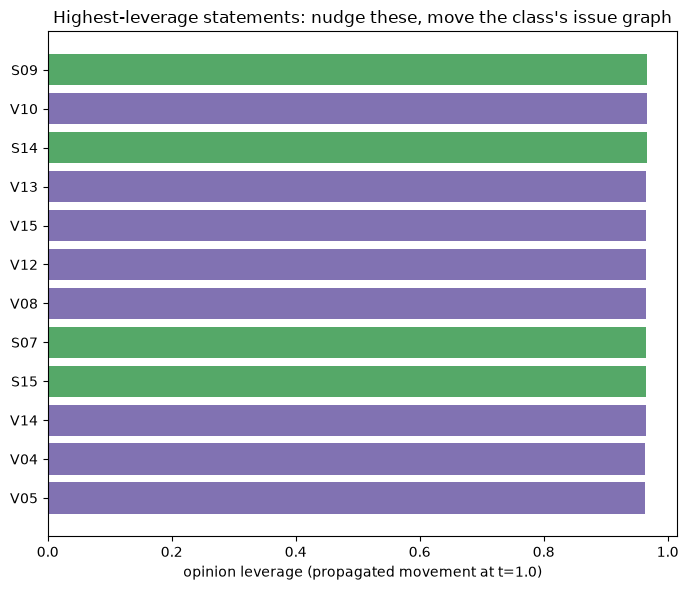

## Summary

See `FINDINGS.md` in this folder for the running bullet list of results with
figure references, kept up to date as this notebook runs.

## 9. Leverage grouped by survey block

The leverage ranking is per-statement. Grouping it by the survey's own
T/E/S/V blocks is the direct point of contact with the agreement network:
member A finds that the two student blocs are separated almost entirely by
S and V items, and if that is real, S and V statements should also be the
ones whose perturbation moves the rest of the issue graph the most.

       count    mean     std     min     max
block                                       
T         13  0.7138  0.2486  0.2329  0.9532
E         15  0.7620  0.2348  0.3401  0.9627
S         15  0.9326  0.0539  0.7845  0.9674
V         15  0.9572  0.0136  0.9139  0.9665


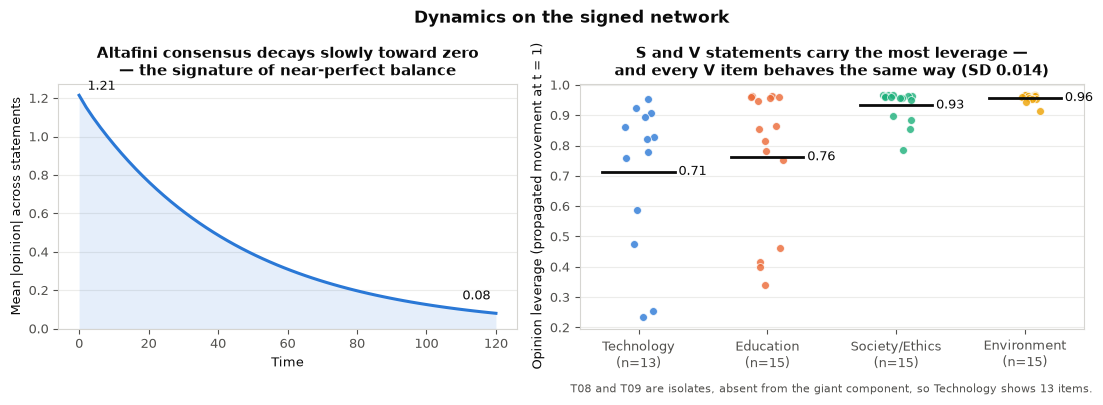

In [17]:
lev_by_block = (lev_df.groupby("block")["leverage"]
                .agg(["count", "mean", "std", "min", "max"])
                .reindex(["T", "E", "S", "V"]).round(4))
lev_by_block.to_csv(TAB_DIR / "table07_leverage_by_block.csv")
print(lev_by_block.to_string())

order = ["T", "E", "S", "V"]
counts = lev_df["block"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.1]})

# ---- (a) Altafini signed consensus ----
ax = axes[0]
mean_abs_traj = np.mean(np.abs(demo["trajectory"]), axis=1)
ax.plot(demo["t_points"], mean_abs_traj, color=viz.CAT[0], lw=2.2)
ax.fill_between(demo["t_points"], 0, mean_abs_traj, color=viz.CAT[0], alpha=0.12, lw=0)
ax.annotate(f"{mean_abs_traj[0]:.2f}", (demo["t_points"][0], mean_abs_traj[0]),
            xytext=(6, 4), textcoords="offset points", fontsize=9, color=viz.INK)
ax.annotate(f"{mean_abs_traj[-1]:.2f}", (demo["t_points"][-1], mean_abs_traj[-1]),
            xytext=(-4, 10), textcoords="offset points", ha="right", fontsize=9, color=viz.INK)
ax.set_xlabel("Time")
ax.set_ylabel("Mean |opinion| across statements")
ax.set_title("Altafini consensus decays slowly toward zero\n"
             "— the signature of near-perfect balance", fontsize=10.5)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, None)

# ---- (b) leverage by block ----
ax = axes[1]
for k, b in enumerate(order):
    vals = lev_df.loc[lev_df["block"] == b, "leverage"].to_numpy()
    jitter = np.random.default_rng(SEED + k).uniform(-0.13, 0.13, size=len(vals))
    ax.scatter(np.full_like(vals, k) + jitter, vals, s=32, color=viz.BLOCK_COLORS[b],
               alpha=0.8, edgecolor="white", linewidth=0.6, zorder=3)
    m = vals.mean()
    ax.plot([k - 0.28, k + 0.28], [m, m], color=viz.INK, lw=2, zorder=4)
    ax.text(k + 0.31, m, f"{m:.2f}", va="center", fontsize=9, color=viz.INK)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{viz.BLOCK_NAMES[b]}\n(n={counts[b]})" for b in order])
ax.set_ylabel("Opinion leverage (propagated movement at t = 1)")
ax.set_title("S and V statements carry the most leverage —\n"
             "and every V item behaves the same way (SD 0.014)", fontsize=10.5)
ax.grid(axis="x", visible=False)
ax.text(0.5, -0.26, "T08 and T09 are isolates, absent from the giant component, so Technology shows 13 items.",
        transform=ax.transAxes, ha="center", fontsize=8, color=viz.INK_SOFT)

fig.suptitle("Dynamics on the signed network", fontsize=12.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig04_dynamics.png")
plt.show()

## 10. Export for Gephi

Both the full signed network and its giant component are written to `gexf/`
with block, community, degree, strength and faction attached as node
attributes, and the correlation and its sign attached to every edge.

In [18]:
GEXF_DIR = Path("gexf")
GEXF_DIR.mkdir(exist_ok=True)

hub_idx = hubs.set_index("item")
faction_map = dict(zip(faction_df["item"], faction_df["faction"]))

for name, Gx in [("signed_statement_network", G),
                 ("signed_statement_giant_component", Gc)]:
    H = Gx.copy()
    nx.set_node_attributes(H, {n: comm[n] for n in H}, "community")
    nx.set_node_attributes(H, {n: blocks[n] for n in H}, "block")
    nx.set_node_attributes(H, {n: int(hub_idx.loc[n, "degree"]) for n in H}, "degree")
    nx.set_node_attributes(H, {n: float(hub_idx.loc[n, "total_strength"]) for n in H}, "strength")
    nx.set_node_attributes(H, {n: int(faction_map.get(n, 0)) for n in H}, "faction")
    nx.write_gexf(H, GEXF_DIR / f"{name}.gexf")
    print(f"gexf/{name}.gexf  ({H.number_of_nodes()} nodes, {H.number_of_edges()} edges)")

gexf/signed_statement_network.gexf  (60 nodes, 402 edges)
gexf/signed_statement_giant_component.gexf  (58 nodes, 402 edges)
